# Sandbox: real MUSE spectrum fitting with kinextract

A clean, self-contained playground for fitting a **real** MUSE spectrum -- any single
spaxel, or a circular/box aperture summed from several -- with the current
kinextract code, and exploring every `FitConfig` knob interactively, including
continuum-cofitting.

Everything you'd want to change lives in the numbered **Parameters** cells below
(spaxel/aperture selection, then the full `FitConfig`). Re-run from a parameters cell
down after changing anything above it.

Always imports from kinextract fresh (via `sys.path`, not a pinned/installed
copy), so this reflects whatever is currently in `src/kinextract/` -- the same
convention `sandbox_synthetic_fit.ipynb` (this directory) uses.

**Unlike the synthetic sandbox**, there is no ground truth here -- `chi2_red`, the
bootstrap uncertainty, and the shape residual are the best available internal
checks, not a correctness guarantee (see `05_real_data_muse.ipynb`'s own
limitations section).

In [1]:
import sys, os

# Assumes this notebook stays in dev_notes/scratch_notebooks/ (repo layout: <repo>/src).
# Edit this path directly if you move the notebook elsewhere.
SRC_DIR = "/Users/waterstk/Documents/Gultekin_Astrophysics/kinextract/src"
sys.path.insert(0, SRC_DIR)

import dataclasses
import warnings
import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, compute_losvd_moments, mask_wavelength_windows,
    load_emiles_templates, load_muse_cube, extract_aperture_spectrum, white_light_image,
    bootstrap_losvd, detect_emission_lines,
)
from kinextract.multi_template import fit_losvd
from kinextract.bias_correction import estimate_snr_whitened
from kinextract.template_reduction import load_template_subset

import kinextract
print(f"kinextract version: {kinextract.__version__ if hasattr(kinextract, '__version__') else '(dev)'}")
print(f"loaded from: {kinextract.__file__}")

kinextract version: 0.2.0
loaded from: /Users/waterstk/Documents/Gultekin_Astrophysics/kinextract/src/kinextract/__init__.py


## 1. Load the real MUSE cube

Points at the same downloaded NGC 5102 cube the other real-data notebooks use by
default -- swap `CUBE_PATH` for any other MUSE Phase 3 cube you have on disk
(`load_muse_cube`'s own docstring: standard ESO Phase 3 `DATA`/`STAT` layout).
`Z` is this target's own systemic redshift; change it if you swap cubes.

cube shape: (3681, 317, 318) (n_wave, ny, nx), pixel_scale=0.20000000000000015"


/var/folders/zp/_mj2qgk5107f3gf_2gnw4gnm0000gs/T/ipykernel_8483/652277103.py:13: RuntimeWarning: divide by zero encountered in log10
  im = ax.imshow(np.where(white_light > 0, np.log10(white_light), np.nan), origin="lower", cmap="inferno")
/var/folders/zp/_mj2qgk5107f3gf_2gnw4gnm0000gs/T/ipykernel_8483/652277103.py:13: RuntimeWarning: invalid value encountered in log10
  im = ax.imshow(np.where(white_light > 0, np.log10(white_light), np.nan), origin="lower", cmap="inferno")


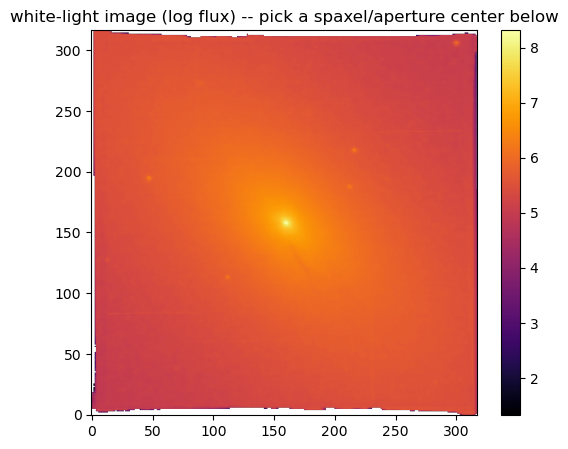

In [2]:
CUBE_PATH = "../../examples/notebooks/muse_download/ADP.2017-03-22T15:25:58.757.fits"
Z = 468.0 / 299792.458  # NGC 5102 systemic velocity ~468 km/s (NED) -- no redshift header in this FITS file

cube = load_muse_cube(CUBE_PATH)
ny, nx = cube.shape
print(f"cube shape: {cube.flux.shape} (n_wave, ny, nx), pixel_scale={cube.pixel_scale}\"")

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    white_light = white_light_image(cube)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(np.where(white_light > 0, np.log10(white_light), np.nan), origin="lower", cmap="inferno")
ax.set_title("white-light image (log flux) -- pick a spaxel/aperture center below")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.show()

## 1b. Optional: ZAP sky-residual cleaning

[ZAP](https://zap.readthedocs.io/) (Zurich Atmosphere Purge, Soto et al. 2016) removes
residual sky-subtraction structure (OH-airglow leftovers) from a MUSE cube via PCA/SVD
on designated sky pixels -- a more principled, cube-level alternative to the fixed
`SKY_RESIDUAL_WINDOWS` list every real-data notebook in this package hardcodes (found
once on this target, reused everywhere). See `zap_cleaning.py` (this directory) for the
wrapper used below.

**This is not a substitute for the emission-line masking in Section 4** -- ZAP explicitly
does not (and should not be relied on to) remove real astrophysical emission; its own docs
warn the opposite risk (too many eigenvectors can subtract genuine emission signal along
with sky residuals). It is also not expected to fully explain a fit whose chi2_red is far
from 1 for other reasons (unmodeled continuum shape, template mismatch, mis-scaled noise).

**Runtime is genuinely multi-minute** on a full cube (not a hang) -- this cell caches its
output to disk and reuses it on subsequent runs, so you only pay that cost once.


In [3]:
USE_ZAP_CLEANED_CUBE = False  # set True to clean sky-subtraction residuals via ZAP first
ZAP_OUTPUT_PATH = CUBE_PATH.replace(".fits", "_zap.fits")

if USE_ZAP_CLEANED_CUBE:
    from zap_cleaning import run_zap_cleaning

    if os.path.exists(ZAP_OUTPUT_PATH):
        print(f"reusing existing ZAP-cleaned cube: {ZAP_OUTPUT_PATH}")
    else:
        print("running ZAP -- a one-time, multi-minute cube-level cleaning pass "
              "(expect several minutes on a full MUSE cube); cached to disk afterward.")
        run_zap_cleaning(CUBE_PATH, output_cube_path=ZAP_OUTPUT_PATH)

    cube = load_muse_cube(ZAP_OUTPUT_PATH)
    print(f"now using the ZAP-cleaned cube: {ZAP_OUTPUT_PATH}")
else:
    print("using the raw (non-ZAP-cleaned) cube -- set USE_ZAP_CLEANED_CUBE=True above to try ZAP")


using the raw (non-ZAP-cleaned) cube -- set USE_ZAP_CLEANED_CUBE=True above to try ZAP


## 2. Dartboard-bin the cube (reflected sin(theta), PA-aware)

Same scheme `dev_notes/scratch_notebooks/ppxf_vs_kinextract_comparison.ipynb` uses:
radial annuli log-spaced in `r`, crossed with angular sectors equally spaced in
`sin(theta)` measured from the kinematic major axis (`PA_DEG`) -- finest near the
major axis, coarsest near the minor axis, matching the `sco_framework` pipeline's
own `bin_r.out`/`bin_v.out` convention (see `dartboard_pa.py`'s own module
docstring). Every one of the 4 reflected wedges is its own independent bin (no
combination across the major/minor axis).

179 dartboard bins (15 radial x 20 angular, PA=135.8 deg, RMAX=13.0", center pixel=(160, 158))


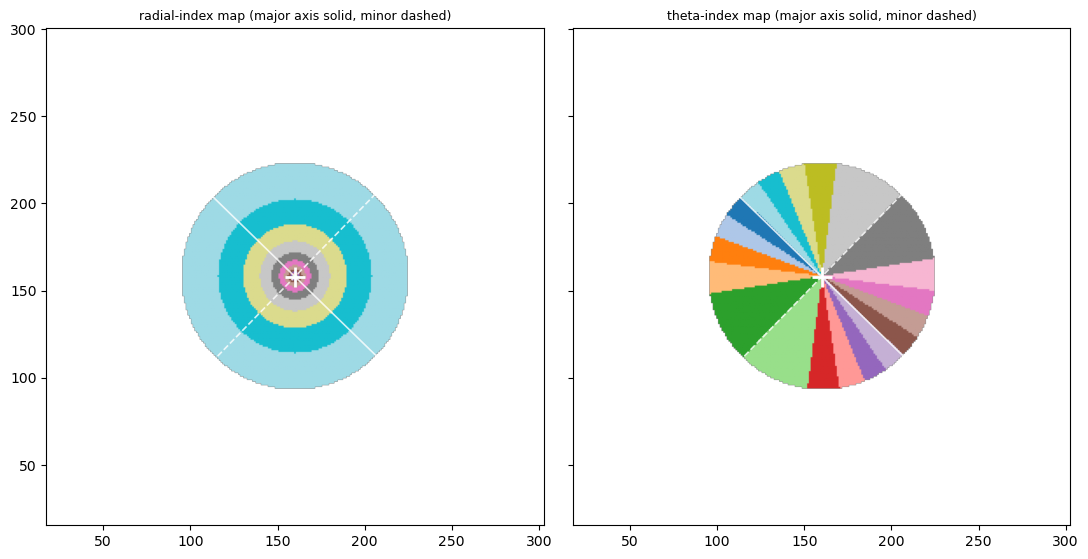

In [4]:
import warnings
from dartboard_pa import build_pa_dartboard

PA_DEG = 45.77 + 90.0   # NGC 5102's own kinematic major-axis PA -- change for a different target
RMAX_ARCSEC = 13.0
N_THETA_PER_QUADRANT = 5   # 5 matches sco_framework's own bin_v.out exactly
REFERENCE_R_EDGES_ARCSEC = np.array([
    0.021, 0.048, 0.088, 0.147, 0.235, 0.365, 0.557, 0.841, 1.261, 1.883,
    2.801, 4.160, 6.171, 9.143, 13.540, 20.044, 29.662, 43.888,
])  # sco_framework's own N5102 MUSE radial bin edges (bin_r.out's "rup" column) -- rescaled/truncated below

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    signal_map = np.nanmedian(cube.flux, axis=0)
    noise_map = np.nanmedian(cube.error, axis=0)
good0 = np.isfinite(signal_map) & np.isfinite(noise_map) & (signal_map > 0) & (noise_map > 0)

yy, xx = np.indices((ny, nx))
x_arcsec = (xx - (nx - 1) / 2.0) * cube.pixel_scale
y_arcsec = (yy - (ny - 1) / 2.0) * cube.pixel_scale

brightest_y, brightest_x = np.unravel_index(np.nanargmax(np.where(good0, signal_map, np.nan)), signal_map.shape)
r_arcsec = np.hypot(x_arcsec - x_arcsec[brightest_y, brightest_x], y_arcsec - y_arcsec[brightest_y, brightest_x])
good = good0 & (r_arcsec <= RMAX_ARCSEC)

dartboard = build_pa_dartboard(
    good, signal_map, noise_map, x_arcsec, y_arcsec, cube.pixel_scale,
    pa_deg=PA_DEG, rmax_arcsec=RMAX_ARCSEC, reference_r_edges_arcsec=REFERENCE_R_EDGES_ARCSEC,
    n_theta_per_quadrant=N_THETA_PER_QUADRANT,
)
bin_map, nbins = dartboard.bin_map, dartboard.nbins
print(f"{nbins} dartboard bins ({dartboard.bins.n_radial} radial x {dartboard.bins.n_angular} angular, "
      f"PA={PA_DEG:.1f} deg, RMAX={RMAX_ARCSEC:.1f}\", center pixel={dartboard.center_pix})")

pa_rad = np.radians(PA_DEG)
axis_len = 0.9 * min(nx, ny) / 2
fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharex=True, sharey=True)
for ax, index_map, label in zip(axes, [dartboard.r_index_map, dartboard.theta_index_map], ["radial", "theta"]):
    ax.imshow(index_map, origin="lower", cmap="tab20")
    ax.plot(dartboard.center_pix[0], dartboard.center_pix[1], "+", color="white", ms=14, mew=2)
    for ang, style in [(pa_rad, "-"), (pa_rad + np.pi / 2, "--")]:
        ax.plot([dartboard.center_pix[0] - axis_len * np.cos(ang), dartboard.center_pix[0] + axis_len * np.cos(ang)],
                [dartboard.center_pix[1] - axis_len * np.sin(ang), dartboard.center_pix[1] + axis_len * np.sin(ang)],
                style, color="white", lw=1.2, alpha=0.8)
    ax.set_title(f"{label}-index map (major axis solid, minor dashed)", fontsize=9)
    ax.set_ylim(dartboard.center_pix[1] - axis_len, dartboard.center_pix[1] + axis_len)
    ax.set_xlim(dartboard.center_pix[0] - axis_len, dartboard.center_pix[0] + axis_len)
plt.tight_layout(); plt.show()

## 3. Pick a specific radial/angular bin to fit

`R_INDEX=0` is always the single central bin (no angular subdivision -- `THETA_INDEX`
is ignored). `R_INDEX>=1` selects one of the `4*N_THETA_PER_QUADRANT` angular
sectors at that radius; read valid `(R_INDEX, THETA_INDEX)` combinations off the
index maps plotted above (a sector fully outside the cube's good spaxels, or
outside `RMAX_ARCSEC`, has no populated bin -- you'll get a clear error below, not
a silent wrong answer).

**Small `R_INDEX` values are often empty, by construction, not a bug.** `REFERENCE_R_EDGES_ARCSEC` starts at sub-arcsecond scales (0.02-0.1") finer than a MUSE pixel (0.2"), inherited from `sco_framework`'s own reference binning -- the innermost few annuli can fall entirely within one pixel and never receive a spaxel at this field of view. The index maps plotted above are the ground truth for which `(R_INDEX, THETA_INDEX)` pairs are actually populated; the `ValueError` below is this notebook telling you a pair isn't, not a real error.

selected bin_id=9: r_index=6, theta_index=1, 1 spaxels, S/N~108.7


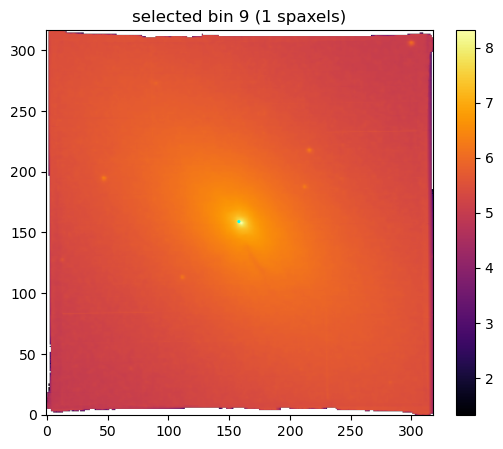

In [5]:
R_INDEX = 6     # 0 = the single center bin; small r_index values can be empty (see note above)
THETA_INDEX = 1  # 0 .. (4*N_THETA_PER_QUADRANT - 1); ignored when R_INDEX == 0

if R_INDEX == 0:
    sel = dartboard.r_index_map == 0
else:
    sel = (dartboard.r_index_map == R_INDEX) & (dartboard.theta_index_map == THETA_INDEX)
if not np.any(sel):
    raise ValueError(f"no populated bin at r_index={R_INDEX}, theta_index={THETA_INDEX} -- "
                     "pick a combination visible in the index maps plotted above")

bin_id = int(bin_map[sel][0])
spaxel_mask = bin_map == bin_id
print(f"selected bin_id={bin_id}: r_index={R_INDEX}, theta_index={THETA_INDEX if R_INDEX else None}, "
      f"{spaxel_mask.sum()} spaxels, S/N~{dartboard.bin_sn[bin_id]:.1f}")

wave_obs, flux_obs, error_obs = extract_aperture_spectrum(cube, spaxel_mask)

fig, ax = plt.subplots(figsize=(6, 5))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    warnings.filterwarnings("ignore", message="divide by zero encountered in log10", category=RuntimeWarning)
    warnings.filterwarnings("ignore", message="invalid value encountered in log10", category=RuntimeWarning)
    white_light = white_light_image(cube)
    im = ax.imshow(np.where(white_light > 0, np.log10(white_light), np.nan), origin="lower", cmap="inferno")
ax.contour(spaxel_mask.astype(float), levels=[0.5], colors="cyan", linewidths=1.5)
ax.set_title(f"selected bin {bin_id} ({spaxel_mask.sum()} spaxels)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.show()

## 4. Deredshift, restrict to the fit window, mask known sky residuals and detected emission lines

Same CaII-triplet window and fixed sky-residual windows every real-data notebook in
this package uses (`VALIDATION_CAMPAIGN.md` Stage 4) -- these were found once on
this target and are reused rather than re-derived per spaxel. If you point this at
a different galaxy/instrument, re-check both.

The sky-residual windows are a fixed list (known bad wavelengths for this
instrument/reduction, not a property of any one spectrum). Emission-line
contamination is different: whether a line is actually in emission depends on
*this* spaxel, so `detect_emission_lines` re-checks it per spectrum via local
excess S/N over the flanking continuum, rather than masking a fixed line list
unconditionally. Unmasked emission biases the recovered LOSVD -- inflated sigma in
particular, since the fitter broadens the LOSVD trying to explain a narrow emission
spike no stellar template can produce.


no candidate emission lines detected in this spaxel/aperture
306 pixels in the fit window (15 masked: sky residuals + detected emission)
rough per-pixel S/N: 85.2


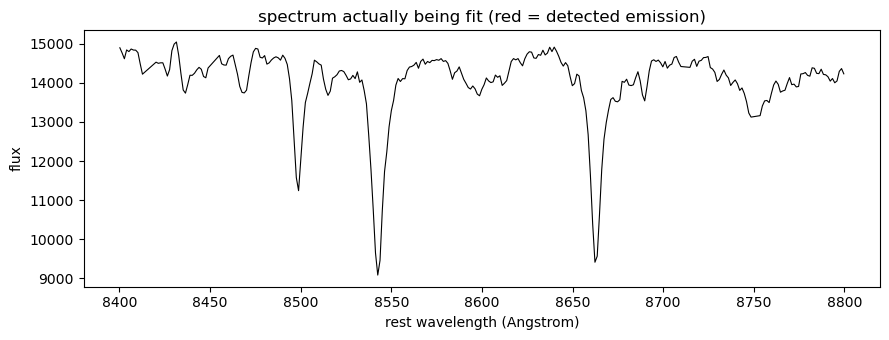

In [6]:
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0  # CaII-triplet rest-frame fit window
SKY_RESIDUAL_WINDOWS = [
    (8414.0, 8419.0), (8449.0, 8454.0), (8711.0, 8714.0), (8748.5, 8753.0),
]
EMISSION_SNR_THRESHOLD = 3.0  # detect_emission_lines' own default; lower = more sensitive

wave_rest = wave_obs / (1.0 + Z)
in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
wave_windowed, flux_windowed, error_windowed = wave_rest[in_window], flux_obs[in_window], error_obs[in_window]

emission_windows = detect_emission_lines(
    wave_windowed, flux_windowed, error_windowed, snr_threshold=EMISSION_SNR_THRESHOLD,
)
if emission_windows:
    print(f"detected emission in {len(emission_windows)} line window(s): {emission_windows}")
else:
    print("no candidate emission lines detected in this spaxel/aperture")

all_windows = SKY_RESIDUAL_WINDOWS + emission_windows
wave_fit, flux_fit = mask_wavelength_windows(wave_windowed, flux_windowed, windows=all_windows)
_, errors = mask_wavelength_windows(wave_windowed, error_windowed, windows=all_windows)

n_before = len(wave_windowed)
print(f"{len(wave_fit)} pixels in the fit window ({n_before - len(wave_fit)} masked: sky residuals + detected emission)")
print(f"rough per-pixel S/N: {np.nanmedian(flux_fit / errors):.1f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(wave_fit, flux_fit, lw=0.8, color="k")
for lo, hi in emission_windows:
    ax.axvspan(lo, hi, color="crimson", alpha=0.25, lw=0)
ax.set_xlabel("rest wavelength (Angstrom)"); ax.set_ylabel("flux")
ax.set_title("spectrum actually being fit (red = detected emission)")
plt.tight_layout(); plt.show()


## 5. Templates

E-MILES SSPs, via the same saved template-conditioning subset
`04_template_calibration.ipynb` derived for this target (every template whose NNLS
weight survived iterative reduction on at least one of its dartboard bins) -- the
current package-recommended default, not a hand-picked list. Set
`USE_TEMPLATE_SUBSET = False` to instead use `MANUAL_TEMPLATE_SELECT` directly if
you want to try a different/smaller template set (e.g. to stress-test template-
mixture identifiability, per `AUDIT_BRIEFING.md`'s own note on that).

In [7]:
EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
TEMPLATE_SUBSET_PATH = "../../examples/data/muse/ngc5102_template_subset.npz"

USE_TEMPLATE_SUBSET = True
MANUAL_TEMPLATE_SELECT = [(1.0, -0.66), (5.0, 0.06), (14.0, 0.40)]  # only used if USE_TEMPLATE_SUBSET=False

if USE_TEMPLATE_SUBSET:
    subset = load_template_subset(TEMPLATE_SUBSET_PATH)
    union_idx = subset["union_selected"]
    select = list(zip(subset["template_ages"][union_idx].tolist(), subset["template_metals"][union_idx].tolist()))
else:
    select = MANUAL_TEMPLATE_SELECT

templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID, select=select)
print(f"loaded {len(templates)} templates:")
for n, a, m in zip(names, ages, metals):
    print(f"  {n}  age={a:.2f} Gyr  [M/H]={m:+.2f}")

loaded 9 templates:
  Ebi1.30Zm0.35T06.5000_iTp0.00_baseFe.fits  age=6.50 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.35T07.0000_iTp0.00_baseFe.fits  age=7.00 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.35T07.5000_iTp0.00_baseFe.fits  age=7.50 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.66T00.0300_iTp0.00_baseFe.fits  age=0.03 Gyr  [M/H]=-0.66
  Ebi1.30Zp0.15T00.0300_iTp0.00_baseFe.fits  age=0.03 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.15T00.0400_iTp0.00_baseFe.fits  age=0.04 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.15T02.7500_iTp0.00_baseFe.fits  age=2.75 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.15T03.5000_iTp0.00_baseFe.fits  age=3.50 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.26T03.0000_iTp0.00_baseFe.fits  age=3.00 Gyr  [M/H]=+0.26


## 6. `FitConfig` -- every knob, one place

Grouped the same way `FitConfig.describe()` groups them. Defaults below match the
package's own shipped defaults (`penalty_order=3`, adaptive `lam_selection`,
continuum-cofitting off) -- change whatever you're exploring and re-run from here
down. Run `FitConfig.describe()` (or `FitConfig.describe("continuum")` to filter)
in a scratch cell any time for the full explanation behind any single field.

**Continuum-cofitting note** (`kinextract.continuum`, still maturing --
see its own module docstring and `dev_notes/continuum/FINDINGS.md` for the
multi-seed validation this package has/hasn't done): adaptive `lam_selection`
does not support it yet -- turning `CONTINUUM_KNOTS` on below auto-switches
`LAM_SELECTION` to `"fixed"` a few cells down if you left it on `"aic_local"`,
with a printed note, rather than silently erroring.

In [8]:
# --- LOSVD grid & spline ---
NSIG = 7                    # velocity half-range for the centered refit, in multiples of the wide-pass sigma
N_INTERIOR_KNOTS = None     # None -> auto-scale via KNOT_SPACING_KMS (recommended); set an int to pin a count
KNOT_SPACING_KMS = 95.0     # target km/s per knot when N_INTERIOR_KNOTS is None
DEGREE = 3                  # spline degree

# --- regularization ---
PENALTY_ORDER = 3           # 3 (default, shrinks toward Gaussian) or 2 (legacy, real wing-inflation risk)
LAM_SELECTION = "aic_local" # "aic_local" (adaptive, recommended) or "fixed"
LAM = 2.0                   # only used if LAM_SELECTION="fixed" (or continuum-cofitting forces it, see above)
RIDGE_LAM = 1.0
LAM_WING = 0.0               # wing-amplitude penalty; largely superseded by PENALTY_ORDER=3, see PARAMETER_GUIDE.md
TAPER_SFAC = 1.8
TAPER_POWER = 4.0
N_SIGL0_ITER = 3
MAX_EDGE_AMPLITUDE_FRAC = 0.01  # real-data sigma-inflation guard -- see FitConfig.describe("max_edge_amplitude_frac")
LOSVD_SINGLE_START = False   # True disables multi-start (ablation only, not recommended)

# --- continuum-cofitting (off by default) ---
CONTINUUM_KNOTS = None       # None -> off; an int (e.g. 4) turns on joint continuum-in-the-model fitting
LAM_C = 2.0
RIDGE_C = 0.1

# --- reporting ---
FIT_H3H4 = True

cfg_kwargs = dict(
    n_interior_knots=N_INTERIOR_KNOTS, knot_spacing_kms=KNOT_SPACING_KMS, degree=DEGREE,
    penalty_order=PENALTY_ORDER, lam_selection=LAM_SELECTION, lam=LAM, ridge_lam=RIDGE_LAM,
    lam_wing=LAM_WING, taper_sfac=TAPER_SFAC, taper_power=TAPER_POWER, n_sigl0_iter=N_SIGL0_ITER,
    max_edge_amplitude_frac=MAX_EDGE_AMPLITUDE_FRAC, losvd_single_start=LOSVD_SINGLE_START,
    continuum_knots=CONTINUUM_KNOTS, lam_c=LAM_C, ridge_c=RIDGE_C,
)

if CONTINUUM_KNOTS is not None and LAM_SELECTION == "aic_local":
    print("Continuum-cofitting is on but LAM_SELECTION='aic_local' doesn't support it yet -- "
          "switching to LAM_SELECTION='fixed' automatically (fit_losvd would otherwise do this "
          "itself, with a UserWarning, one level down).")
    cfg_kwargs["lam_selection"] = "fixed"

## 7. Fit -- two-stage (wide grid, then a centered refit)

Same two-stage convention `05_real_data_muse.ipynb` uses: a generous fixed-range
first pass just to locate `V`/`sigma` roughly, then a `V +/- NSIG*sigma`-centered
refit using your actual `FitConfig` choices above (this is where `PENALTY_ORDER`/
`LAM_SELECTION`/`CONTINUUM_KNOTS`/etc. all actually apply -- the wide pass always
uses plain defaults, since its only job is finding the right window).

In [9]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    cfg_wide = FitConfig(vmin=-400.0, vmax=400.0)
v_grid_wide = cfg_wide.build_velocity_grid()
A_stack_wide = build_template_stack(wave_fit, template_wave, templates, v_grid_wide)
A_stack_w_wide = A_stack_wide / errors[None, :, None]
y_w = flux_fit / errors
result_wide = fit_losvd(A_stack_w_wide, y_w, cfg_wide)
moments_wide = compute_losvd_moments(v_grid_wide, result_wide["b"], fit_h3h4=False)
print(f"wide pass: V={moments_wide['vherm']:+.1f}  sigma={moments_wide['sherm']:.1f}")

cfg = FitConfig(vmin=moments_wide["vherm"] - NSIG * moments_wide["sherm"],
                vmax=moments_wide["vherm"] + NSIG * moments_wide["sherm"], **cfg_kwargs)
v_grid = cfg.build_velocity_grid()
A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
A_stack_w = A_stack / errors[None, :, None]

wave_arg = wave_fit if cfg.continuum_knots is not None else None
result = fit_losvd(A_stack_w, y_w, cfg, wave_fit=wave_arg)
moments = compute_losvd_moments(v_grid, result["b"], fit_h3h4=FIT_H3H4)

A_eff_w = np.tensordot(result["w"], A_stack_w, axes=([0], [0]))
model_w = A_eff_w @ result["b"]
if cfg.continuum_knots is not None:
    model_w = model_w * result["C"]
chi2_red = float(np.sum((model_w - y_w) ** 2)) / len(wave_fit)
snr_est = estimate_snr_whitened(model_w)

print(f"\nrefit: V={moments['vherm']:+.1f}  sigma={moments['sherm']:.1f}  "
      f"h3={moments['h3']:+.4f}  h4={moments['h4']:+.4f}")
print(f"lam_used={result['lam_used']:.4g}  chi2_red={chi2_red:.2f}  "
      f"snr_estimated={snr_est:.1f}  success={result['success']}")
if cfg.continuum_knots is not None:
    print(f"recovered continuum C: min={result['C'].min():.3f}  max={result['C'].max():.3f}")

wide pass: V=+20.9  sigma=48.0



refit: V=+20.8  sigma=47.0  h3=-0.0000  h4=+0.0001
lam_used=3.277e+04  chi2_red=1.13  snr_estimated=85.6  success=True


## 8. Plot: spectral fit and recovered LOSVD

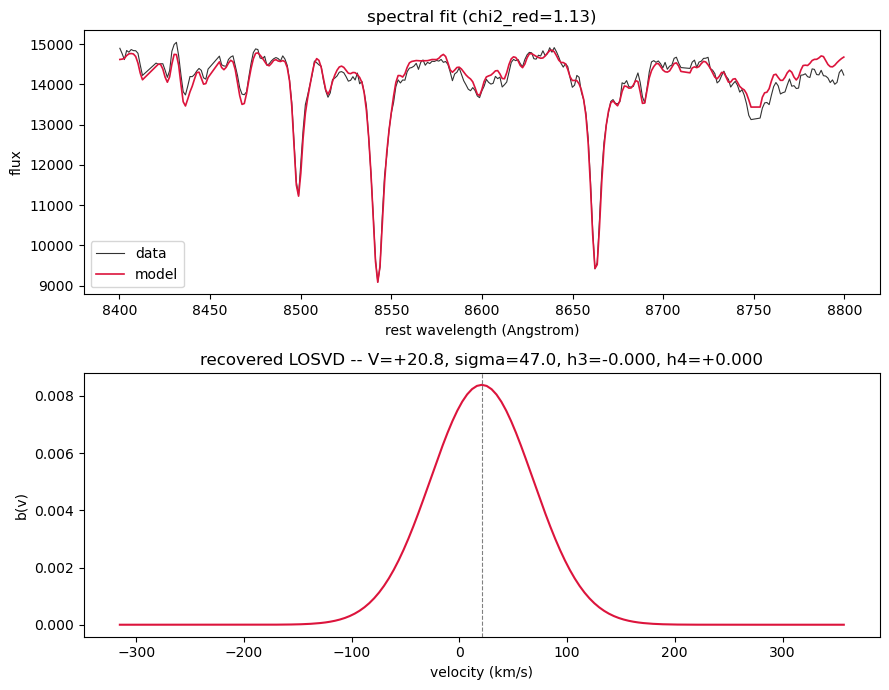

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7))

model = model_w * errors
axes[0].plot(wave_fit, flux_fit, color="black", lw=0.8, alpha=0.8, label="data")
axes[0].plot(wave_fit, model, color="crimson", lw=1.2, label="model")
axes[0].set_xlabel("rest wavelength (Angstrom)"); axes[0].set_ylabel("flux")
axes[0].set_title(f"spectral fit (chi2_red={chi2_red:.2f})")
axes[0].legend()

b_norm = result["b"] / np.trapezoid(np.maximum(result["b"], 0.0), v_grid)
axes[1].plot(v_grid, b_norm, color="crimson", lw=1.5)
axes[1].axvline(moments["vherm"], color="gray", ls="--", lw=0.8)
axes[1].set_xlabel("velocity (km/s)"); axes[1].set_ylabel("b(v)")
axes[1].set_title(f"recovered LOSVD -- V={moments['vherm']:+.1f}, sigma={moments['sherm']:.1f}, "
                  f"h3={moments['h3']:+.3f}, h4={moments['h4']:+.3f}")

plt.tight_layout(); plt.show()

if cfg.continuum_knots is not None:
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(wave_fit, result["C"], color="teal", lw=1.2)
    ax.axhline(1.0, color="gray", ls="--", lw=0.8)
    ax.set_xlabel("rest wavelength (Angstrom)"); ax.set_ylabel("C(lambda)")
    ax.set_title("recovered continuum")
    plt.tight_layout(); plt.show()

## 9. Uncertainty via bootstrap (optional -- costs `N_BOOT` extra fits)

`apply_bias_correction=True` uses the shipped E-MILES multi-template calibration
(`bias_correction.py`) -- see that module's own docstring, and
`uncertainty.py`'s, for its current scope/limitations (opt-in, not yet fully
gate-validated -- see `dev_notes/uncertainty/FINDINGS.md`).

V     = +20.8 +/- 0.9
sigma = 47.0 +/- 2.0
h3    = -0.000 +/- 0.000
h4    = +0.000 +/- 0.000


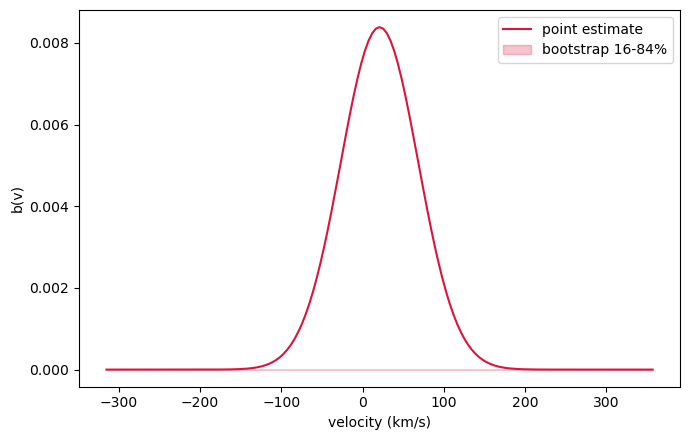

In [11]:
N_BOOT = 10  # real single-spaxel fits run ~5-10x slower than synthetic mocks (~10s/fit, not ~1s) -- raise this once you know your own timing budget
APPLY_BIAS_CORRECTION = False

boot = bootstrap_losvd(A_stack_w, y_w, cfg, n_boot=N_BOOT, seed=0,
                       wave_fit=wave_arg, apply_bias_correction=APPLY_BIAS_CORRECTION)

print(f"V     = {boot['point0']['vherm']:+.1f} +/- {boot['vherm_std']:.1f}")
print(f"sigma = {boot['point0']['sherm']:.1f} +/- {boot['sherm_std']:.1f}"
      + (f"   (corrected: {boot['point0_corrected']['sherm']:.1f} +/- {boot['sherm_std_corrected']:.1f})"
         if APPLY_BIAS_CORRECTION else ""))
print(f"h3    = {boot['point0']['h3']:+.3f} +/- {boot['h3_std']:.3f}")
print(f"h4    = {boot['point0']['h4']:+.3f} +/- {boot['h4_std']:.3f}"
      + (f"   (corrected: {boot['point0_corrected']['h4']:+.3f} +/- {boot['h4_std_corrected']:.3f})"
         if APPLY_BIAS_CORRECTION else ""))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(v_grid, b_norm, color="crimson", lw=1.5, label="point estimate")
# Normalize against the SAME area the point estimate (b_norm) was normalized by,
# not a separate "b_median" key -- bootstrap_losvd only exposes a median under
# that name when apply_bias_correction=True (b_median_corrected); the raw
# ensemble's own median is available as np.median(boot["b_boot"], axis=0) if
# you want it, but reusing b_norm's own area keeps this comparable to the
# point-estimate curve already plotted above.
b_area = np.trapezoid(np.maximum(result["b"], 0.0), v_grid)
b_p16 = boot["b_p16"] / b_area
b_p84 = boot["b_p84"] / b_area
ax.fill_between(v_grid, b_p16, b_p84, color="crimson", alpha=0.25, label="bootstrap 16-84%")
ax.set_xlabel("velocity (km/s)"); ax.set_ylabel("b(v)")
ax.legend(); plt.tight_layout(); plt.show()

## Notes

- This is a **temporary scratch sandbox**, not part of the polished
  `examples/notebooks/` sequence -- see `05_real_data_muse.ipynb` for the
  validated, narrated real-data walkthrough this reuses conventions from.
- Continuum-cofitting is still maturing (`dev_notes/continuum/FINDINGS.md`) --
  treat results with it on as exploratory, especially away from
  `penalty_order=2, lam=2.0` (the one combination with any multi-seed validation).
- No ground truth exists for real data -- `chi2_red`, bootstrap spread, and visual
  residual inspection are the only internal checks available.